In [1]:
import numpy as np
import pandas as pd
from  pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns   
import sys
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_cleaning.main import clean_games_data, clean_moves_data
from src.EDA.helpers import are_there_outliers, spearman_with_target
from src.data_transforming.main import build_features_dataframe
from scipy.stats import spearmanr

/home/javier/Universidad/grupoAries/pruebasML/elo_predictor/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:


dataDirectory = Path.cwd().parents[1] / 'data'

COLUMNS_GAMES = [
    'game_id', 'result', 'white_elo',
    'black_elo', 'time_control', 'termination',
    'num_plies'
]
COLUMNS_MOVES = [
    'game_id', 'ply', 'move_number',
    'eval', 'mate', 'clock'
]

CHUNK_SIZE = 250_000

cleaned_games_chunks : list[pd.DataFrame] = []
cleaned_moves_chunks : list[pd.DataFrame] = []

for chunk in tqdm(pd.read_csv(dataDirectory / 'lichess_db_standard_rated_2018-06_games.csv', chunksize=CHUNK_SIZE), desc='Processing games data', unit='Chunk'):
    cleaned_games_chunks.append(clean_games_data(chunk))

cleaned_games_data = pd.concat(cleaned_games_chunks)

for chunk in tqdm(pd.read_csv(dataDirectory / 'lichess_db_standard_rated_2018-06_moves.csv', chunksize=CHUNK_SIZE), desc='Processing moves data', unit='Chunk'):
    cleaned_moves_chunks.append(clean_moves_data(chunk, cleaned_games_data['game_id']))

cleaned_moves_data = pd.concat(cleaned_moves_chunks)

cleaned_games_data.to_csv(PROJECT_ROOT / 'data' / 'cleaned_games.csv')
cleaned_moves_data.to_csv(PROJECT_ROOT / 'data' / 'cleaned_moves.csv')

In [2]:
dataDirectory = Path.cwd().parents[1] / 'data'

cleaned_games_data = pd.read_csv(dataDirectory / 'cleaned_games.csv')
cleaned_moves_data = pd.read_csv(dataDirectory / 'cleaned_moves.csv')

In [ ]:
cleaned_games_data.head()


In [ ]:
cleaned_moves_data.head(56)

In [ ]:
cleaned_games_data.shape

In [ ]:
cleaned_moves_data.shape

In [ ]:
cleaned_games_data.info()

In [ ]:
cleaned_moves_data.info()

In [ ]:
cleaned_games_data.describe()

In [ ]:
cleaned_games_data['time_control'].value_counts(normalize=True)

In [ ]:
cleaned_games_data['termination'].value_counts()

In [ ]:
X_games = cleaned_games_data.drop(columns=['white_elo', 'black_elo'])
y = cleaned_games_data[['white_elo', 'black_elo']] 

X_moves = cleaned_moves_data

X_train_games, X_test_games, y_train, y_test = train_test_split(X_games, y, test_size=0.2, random_state=0)

## Games data

In [ ]:
NUMERICAL_COLS_TO_PLOT = ['white_elo', 'black_elo', 'num_plies']
NUMERICAL_COLS_IN_X = ['num_plies']

print("--------------------")
for col in NUMERICAL_COLS_TO_PLOT:
    print(f"Name: {col}")
    print("Type: numerical")
    print(f"Are there outliers?: {are_there_outliers(X_train_games if (col in NUMERICAL_COLS_IN_X) else y_train, col)}")
    print(f"% of missing values: {X_train_games[col].isna().mean()*100 if (col in NUMERICAL_COLS_IN_X) else y_train[col].isna().mean()*100}%")
    sns.histplot(data=X_train_games if col in NUMERICAL_COLS_IN_X else y_train, x=col, discrete=True)
    plt.show()
    print("--------------------")

In [ ]:
COLS = ['white_elo', 'black_elo']
for col in COLS:
    rho, p = spearmanr(X_train_games['num_plies'], y_train[col])
    print(f"rho={rho:.3f}, p={p:.2e}")
    sns.scatterplot(data=X_train_games, x=y_train[col], y='num_plies', alpha=0.2, s=5)
    plt.show()

    

In [ ]:
sns.boxplot(data=X_train_games,x = 'termination', y=y_train['black_elo'])
plt.show()

sns.boxplot(data=X_train_games,x = 'termination', y=y_train['white_elo'])
plt.show()

In [ ]:
sns.boxplot(data=X_train_games,x = 'result', y=y_train['black_elo'])
plt.show()

sns.boxplot(data=X_train_games,x = 'result', y=y_train['white_elo'])
plt.show()

In [3]:
g = build_features_dataframe(cleaned_moves_data, cleaned_games_data)

In [4]:
g.head()

,game_id,num_plies,base_time,increment_per_move,termination_normal,termination_time,is_white,elo,result_win,result_loss,...,avg_win%_loss,highest_win%_loss,num_unseen_checkmates,time_spent_1_to_5_moves,time_spent_6_to_10_moves,opp_avg_win%_loss,opp_highest_win%_loss,opp_num_unseen_checkmates,opp_time_spent_6_to_10_moves,opp_time_spent_1_to_5_moves
0,QuEQ3dBV,66,600,0,True,False,1,1556,0,1,...,4.038328,60.079315,0,14.0,40.0,2.596432,22.943727,0,89.0,48.0
1,MQHorkOO,59,600,0,True,False,1,985,1,0,...,8.663541,75.094179,0,22.0,18.0,10.475796,90.011631,1,39.0,21.0
2,3B4avRhC,41,600,0,True,False,1,1739,1,0,...,3.031279,22.480301,0,17.0,82.0,5.214621,26.752198,0,61.0,11.0
3,1XmaeJMU,51,600,0,True,False,1,1063,1,0,...,1.239211,9.048893,0,6.0,12.0,2.997539,16.070164,0,16.0,12.0
4,wY1TtXW0,112,900,0,True,False,1,1505,0,1,...,3.082308,14.986071,0,12.0,27.0,2.240150,11.770075,0,10.0,3.0


In [5]:
g.to_csv(dataDirectory / 'features.csv', index=False)

In [ ]:
g.shape

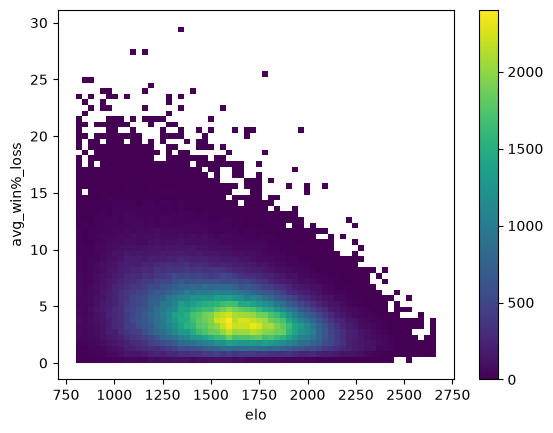

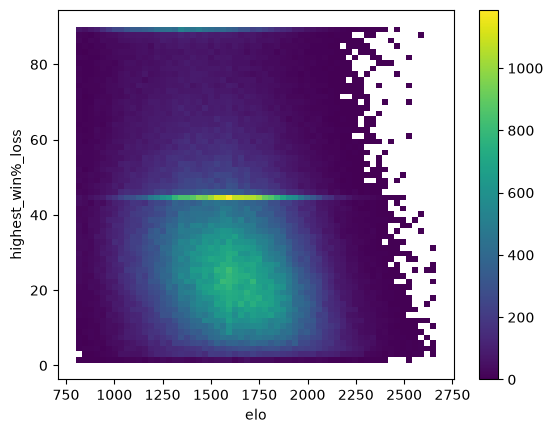

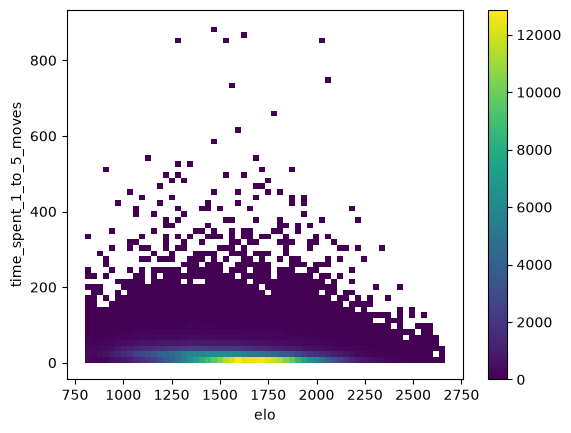

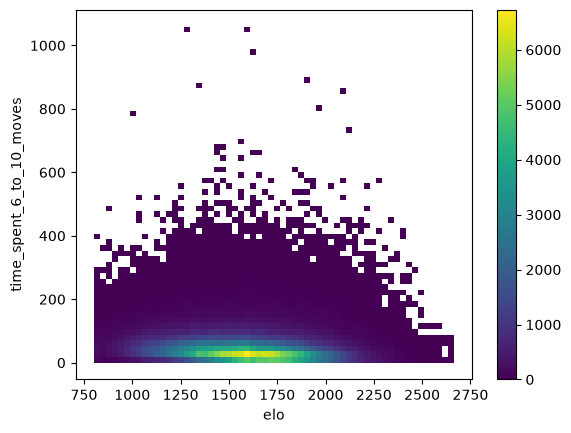

In [7]:
Y_TO_PLOT = ['avg_win%_loss', 'highest_win%_loss', 'time_spent_1_to_5_moves', 'time_spent_6_to_10_moves']

for col in Y_TO_PLOT:
    sns.histplot(data=g, x='elo', y=col, bins=60, cbar=True, cmap='viridis')
    plt.show()

In [ ]:
g['elo_bin'] = pd.cut(g['elo'], bins=range(800, 2800, 100))
sns.barplot(data=g, x='elo_bin', y='num_unseen_checkmates')
plt.xticks(rotation=90)
plt.show()

In [9]:
spearman_with_target(g, 'elo', ['avg_win%_loss', 'highest_win%_loss', 'num_plies', 'num_unseen_checkmates', 'time_spent_1_to_5_moves', 'time_spent_6_to_10_moves'])

time_spent_1_to_5_moves    -0.306514
avg_win%_loss              -0.270121
highest_win%_loss          -0.219357
time_spent_6_to_10_moves   -0.190352
num_unseen_checkmates      -0.101392
num_plies                   0.141813
dtype: float64

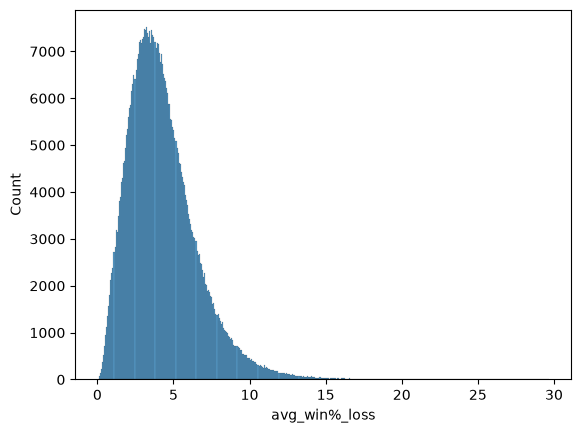

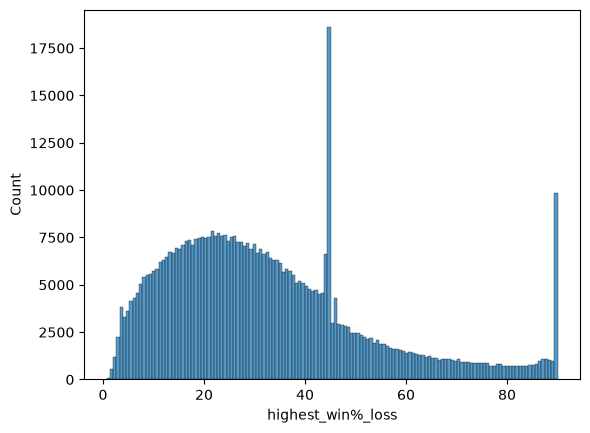

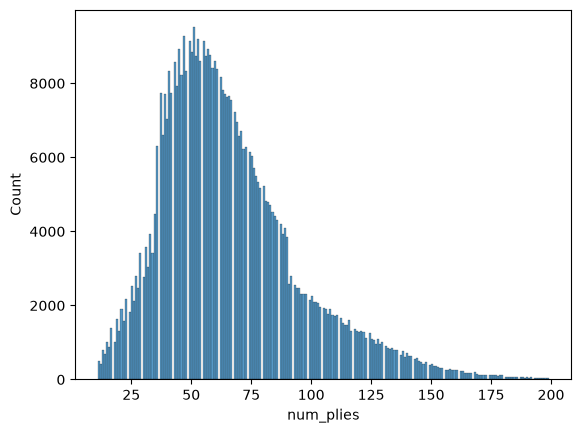

In [10]:
NUM_COLS = ['avg_win%_loss', 'highest_win%_loss', 'num_plies']
for col in NUM_COLS:
    sns.histplot(data=g, x=col)
    plt.show()